### Resumen del Modelo
- **Estados ocultos ($S$):** `Sano`, `Desgaste`, `Crítico` (condición mecánica interna real no observable directamente).
- **Observaciones visibles ($V$):** Vibración `Baja`, `Media`, `Alta` (lectura del sensor externo en cada ciclo $t$).
- **Componentes formales $\lambda = (S, V, A, B, \pi)$:** Probabilidades iniciales $\pi$, matriz de transición de estados $A$ y matriz de emisión de vibraciones $B$.
- **Mejoras Estándar Q1 incluidas:**
  1. **Evaluación Multi-Escenario ($E_1$ a $E_4$):** Variación controlada de $\pi$, $A$ y $B$ con 500 réplicas Monte Carlo por escenario.
  2. **Estadística Inferencial Completa:** Media, Desviación Estándar, Mínimo, Máximo, **Intervalos de Confianza al 95% ($IC_{95\%}$)**, Matriz de Confusión y Retardo de Detección.
  3. **Los 3 Problemas de Rabiner:** Filtrado Forward escalado, Decodificación de Viterbi y Aprendizaje no supervisado **Baum-Welch (EM)**.

In [20]:
import os
import sys
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

os.makedirs('results', exist_ok=True)
ESTADOS = ['Sano', 'Desgaste', 'Crítico']
ESTADOS_ASCII = ['Sano', 'Desgaste', 'Critico']
OBSERV = ['Baja', 'Media', 'Alta']

print(f'Entorno verificado -> Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}')

Entorno verificado -> Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3


## 1. Especificación Formal del Modelo ($\pi, A, B$) y los 4 Escenarios Experimentales
Se definen las matrices del **Escenario Base ($E_1$)** y las variaciones paramétricas de los escenarios **$E_2$ (Inicio Crítico - variación de $\pi$)**, **$E_3$ (Sobrecarga Industrial - variación de $A$)** y **$E_4$ (Sensor Calibrado - variación de $B$)**.

In [19]:
# Probabilidades iniciales (pi) del Escenario Base
PI = np.array([0.80, 0.18, 0.02])

# Matriz de transición A[i, j] = P(estado_{t+1}=j | estado_t=i)
A = np.array([
    [0.92, 0.07, 0.01],
    [0.05, 0.85, 0.10],
    [0.40, 0.10, 0.50],
])

# Matriz de emisión B[i, k] = P(observación=k | estado=i)
B = np.array([
    [0.75, 0.20, 0.05],
    [0.20, 0.55, 0.25],
    [0.05, 0.25, 0.70],
])

# Definición de los 4 escenarios experimentales (Estándar Q1)
ESCENARIOS = {
    'E1_Base_Nominal': {
        'nombre': 'E1: Base (Operación Nominal)',
        'PI': PI.copy(), 'A': A.copy(), 'B': B.copy()
    },
    'E2_Inicio_Critico': {
        'nombre': 'E2: Inicio Crítico (Variación de π)',
        'PI': np.array([0.05, 0.25, 0.70]), 'A': A.copy(), 'B': B.copy()
    },
    'E3_Degradacion_Severa': {
        'nombre': 'E3: Sobrecarga Industrial (Variación de A)',
        'PI': PI.copy(),
        'A': np.array([[0.82, 0.15, 0.03], [0.03, 0.77, 0.20], [0.25, 0.15, 0.60]]),
        'B': B.copy()
    },
    'E4_Sensor_Alta_Precision': {
        'nombre': 'E4: Sensor Calibrado (Variación de B)',
        'PI': PI.copy(), 'A': A.copy(),
        'B': np.array([[0.90, 0.08, 0.02], [0.08, 0.82, 0.10], [0.02, 0.10, 0.88]])
    },
}

assert np.isclose(PI.sum(), 1.0) and np.allclose(A.sum(axis=1), 1.0) and np.allclose(B.sum(axis=1), 1.0)
display(pd.DataFrame([PI], columns=ESTADOS, index=['π (Inicial)']))
display(pd.DataFrame(A, index=ESTADOS, columns=ESTADOS).rename_axis('Matriz de Transición A'))
display(pd.DataFrame(B, index=ESTADOS, columns=['Vib. ' + o for o in OBSERV]).rename_axis('Matriz de Emisión B'))

,Sano,Desgaste,Crítico
π (Inicial),0.8,0.18,0.02


,Sano,Desgaste,Crítico
Matriz de Transición A,,,
Sano,0.92,0.07,0.01
Desgaste,0.05,0.85,0.10
Crítico,0.40,0.10,0.50


,Vib. Baja,Vib. Media,Vib. Alta
Matriz de Emisión B,,,
Sano,0.75,0.20,0.05
Desgaste,0.20,0.55,0.25
Crítico,0.05,0.25,0.70


## 2. Diagrama Topológico del HMM y Flujo Metodológico (F1–F7)
Se genera y visualiza el grafo dirigido de transiciones y emisiones junto con las etapas metodológicas del estudio.

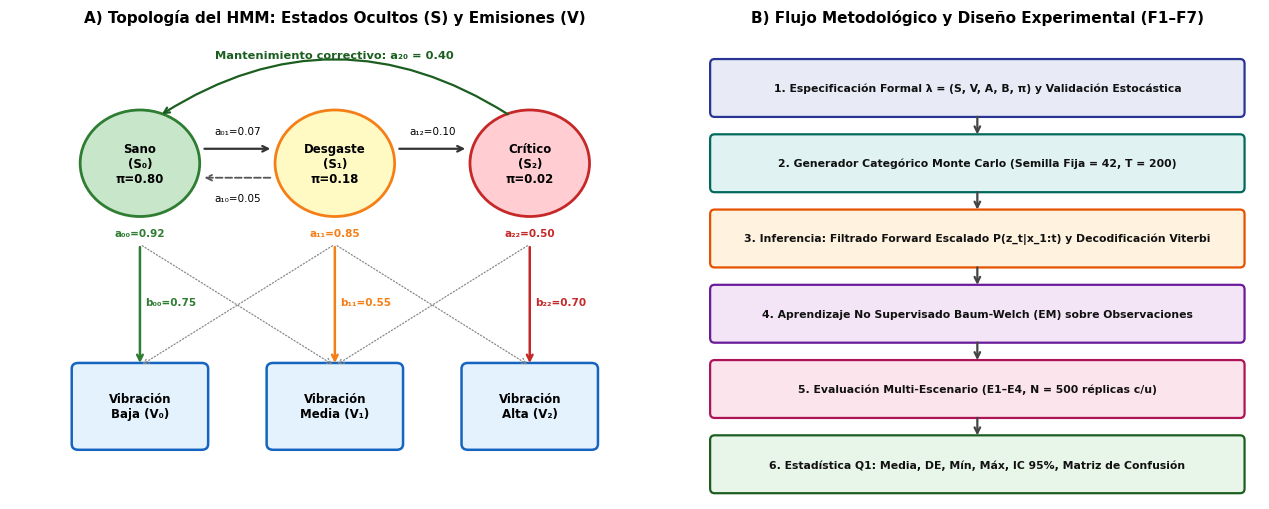

In [3]:
def mostrar_diagrama_metodologico():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.15, 1.0]})
    ax1.set_xlim(0, 10); ax1.set_ylim(0, 8); ax1.axis('off')
    ax1.set_title('A) Topología del HMM: Estados Ocultos (S) y Emisiones (V)', fontsize=11, fontweight='bold', pad=10)

    nodos_s = [(2.0, 5.8, 'Sano\n(S₀)\nπ=0.80', '#c8e6c9', '#2e7d32'),
               (5.0, 5.8, 'Desgaste\n(S₁)\nπ=0.18', '#fff9c4', '#f57f17'),
               (8.0, 5.8, 'Crítico\n(S₂)\nπ=0.02', '#ffcdd2', '#c62828')]
    nodos_v = [(2.0, 1.6, 'Vibración\nBaja (V₀)', '#e3f2fd', '#1565c0'),
               (5.0, 1.6, 'Vibración\nMedia (V₁)', '#e3f2fd', '#1565c0'),
               (8.0, 1.6, 'Vibración\nAlta (V₂)', '#e3f2fd', '#1565c0')]

    for x_p, y_p, lbl, fc, ec in nodos_s:
        ax1.add_patch(plt.Circle((x_p, y_p), 0.92, facecolor=fc, edgecolor=ec, lw=2, zorder=3))
        ax1.text(x_p, y_p, lbl, ha='center', va='center', fontsize=8.5, fontweight='bold', zorder=4)
    for x_p, y_p, lbl, fc, ec in nodos_v:
        ax1.add_patch(FancyBboxPatch((x_p - 0.95, y_p - 0.65), 1.9, 1.3, boxstyle='round,pad=0.1', facecolor=fc, edgecolor=ec, lw=1.8, zorder=3))
        ax1.text(x_p, y_p, lbl, ha='center', va='center', fontsize=8.5, fontweight='bold', zorder=4)

    ax1.annotate('', xy=(4.05, 6.05), xytext=(2.95, 6.05), arrowprops=dict(arrowstyle='->', lw=1.6, color='#333'))
    ax1.text(3.5, 6.3, 'a₀₁=0.07', ha='center', fontsize=7.5)
    ax1.annotate('', xy=(2.95, 5.55), xytext=(4.05, 5.55), arrowprops=dict(arrowstyle='->', lw=1.3, color='#555', ls='--'))
    ax1.text(3.5, 5.15, 'a₁₀=0.05', ha='center', fontsize=7.5)
    ax1.annotate('', xy=(7.05, 6.05), xytext=(5.95, 6.05), arrowprops=dict(arrowstyle='->', lw=1.6, color='#333'))
    ax1.text(6.5, 6.3, 'a₁₂=0.10', ha='center', fontsize=7.5)
    ax1.annotate('', xy=(2.3, 6.62), xytext=(7.7, 6.62), arrowprops=dict(arrowstyle='->', lw=1.6, color='#1b5e20', connectionstyle='arc3,rad=0.32'))
    ax1.text(5.0, 7.62, 'Mantenimiento correctivo: a₂₀ = 0.40', ha='center', fontsize=8.2, color='#1b5e20', fontweight='bold')
    ax1.text(2.0, 4.55, 'a₀₀=0.92', ha='center', fontsize=7.5, color='#2e7d32', fontweight='bold')
    ax1.text(5.0, 4.55, 'a₁₁=0.85', ha='center', fontsize=7.5, color='#f57f17', fontweight='bold')
    ax1.text(8.0, 4.55, 'a₂₂=0.50', ha='center', fontsize=7.5, color='#c62828', fontweight='bold')

    for sx, vx, prob, col in [(2.0, 2.0, 'b₀₀=0.75', '#2e7d32'), (5.0, 5.0, 'b₁₁=0.55', '#f57f17'), (8.0, 8.0, 'b₂₂=0.70', '#c62828')]:
        ax1.annotate('', xy=(vx, 2.3), xytext=(sx, 4.4), arrowprops=dict(arrowstyle='->', lw=1.8, color=col))
        ax1.text((sx + vx) / 2 + 0.48, 3.35, prob, ha='center', fontsize=7.5, color=col, fontweight='bold')
    for sx, vx in [(2.0, 5.0), (5.0, 2.0), (5.0, 8.0), (8.0, 5.0)]:
        ax1.annotate('', xy=(vx, 2.3), xytext=(sx, 4.4), arrowprops=dict(arrowstyle='->', lw=0.9, color='#888', ls=':'))

    ax2.set_xlim(0, 10); ax2.set_ylim(0, 8); ax2.axis('off')
    ax2.set_title('B) Flujo Metodológico y Diseño Experimental (F1–F7)', fontsize=11, fontweight='bold', pad=10)
    pasos_flujo = [
        (7.1, '1. Especificación Formal λ = (S, V, A, B, π) y Validación Estocástica', '#e8eaf6', '#283593'),
        (5.8, '2. Generador Categórico Monte Carlo (Semilla Fija = 42, T = 200)', '#e0f2f1', '#00695c'),
        (4.5, '3. Inferencia: Filtrado Forward Escalado P(z_t|x_1:t) y Decodificación Viterbi', '#fff3e0', '#e65100'),
        (3.2, '4. Aprendizaje No Supervisado Baum-Welch (EM) sobre Observaciones', '#f3e5f5', '#6a1b9a'),
        (1.9, '5. Evaluación Multi-Escenario (E1–E4, N = 500 réplicas c/u)', '#fce4ec', '#ad1457'),
        (0.6, '6. Estadística Q1: Media, DE, Mín, Máx, IC 95%, Matriz de Confusión', '#e8f5e9', '#1b5e20'),
    ]
    for idx_f, (y_p, texto, fc, ec) in enumerate(pasos_flujo):
        ax2.add_patch(FancyBboxPatch((0.35, y_p - 0.42), 9.3, 0.84, boxstyle='round,pad=0.08', facecolor=fc, edgecolor=ec, lw=1.6, zorder=3))
        ax2.text(5.0, y_p, texto, ha='center', va='center', fontsize=7.8, fontweight='bold', color='#111', zorder=4)
        if idx_f < len(pasos_flujo) - 1:
            ax2.annotate('', xy=(5.0, pasos_flujo[idx_f + 1][0] + 0.45), xytext=(5.0, y_p - 0.45), arrowprops=dict(arrowstyle='->', lw=1.6, color='#444'))

    plt.tight_layout()
    plt.savefig('results/diagrama_modelo_hmm.png', dpi=300)
    plt.show()

mostrar_diagrama_metodologico()

## 3. Funciones del Modelo: Simulación, Forward-Backward, Viterbi, Baum-Welch y Estadísticos IC 95%

In [8]:
def simular(T, rng, pi=PI, A=A, B=B):
    """Genera (estados ocultos z, observaciones x) con distribuciones categóricas."""
    z = np.empty(T, dtype=int)
    x = np.empty(T, dtype=int)
    z[0] = rng.choice(len(pi), p=pi)
    x[0] = rng.choice(B.shape[1], p=B[z[0]])
    for t in range(1, T):
        z[t] = rng.choice(len(pi), p=A[z[t - 1]])
        x[t] = rng.choice(B.shape[1], p=B[z[t]])
    return z, x

def forward(x, pi=PI, A=A, B=B):
    """Algoritmo Forward escalado: log-verosimilitud y filtrado P(z_t | x_{1:t})."""
    T = len(x); N = len(pi)
    alfa = np.zeros((T, N)); c = np.zeros(T)
    a = pi * B[:, x[0]]
    c[0] = a.sum(); alfa[0] = a / c[0]
    for t in range(1, T):
        a = (alfa[t - 1] @ A) * B[:, x[t]]
        c[t] = a.sum(); alfa[t] = a / c[t]
    return np.log(c).sum(), alfa, c


def generar_alerta(probabilidades):
    prob_critico = probabilidades[2]

    if prob_critico < 0.30:
        return "Monitoreo normal"
    elif prob_critico < 0.60:
        return "Programar inspeccion"
    else:
        return "Alerta de mantenimiento"




def backward(x, c, A=A, B=B):
    """Algoritmo Backward escalado para suavizado y Baum-Welch."""
    T = len(x); N = A.shape[0]
    beta = np.zeros((T, N)); beta[-1] = 1.0
    for t in range(T - 2, -1, -1):
        beta[t] = (A @ (B[:, x[t + 1]] * beta[t + 1])) / c[t + 1]
    return beta

def viterbi(x, pi=PI, A=A, B=B):
    """Algoritmo de Viterbi en log-espacio: trayectoria de estados ocultos más probable."""
    T = len(x); N = len(pi); eps = 1e-15
    d = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
    d[0] = np.log(pi + eps) + np.log(B[:, x[0]] + eps)
    logA = np.log(A + eps); logB = np.log(B + eps)
    for t in range(1, T):
        m = d[t - 1][:, None] + logA
        psi[t] = m.argmax(axis=0)
        d[t] = m.max(axis=0) + logB[:, x[t]]
    z = np.zeros(T, dtype=int)
    z[-1] = d[-1].argmax()
    for t in range(T - 2, -1, -1):
        z[t] = psi[t + 1, z[t + 1]]
    return z

def baum_welch(secuencias_x, A_init, B_init, pi_init, max_iter=35, tol=1e-4):
    """Aprendizaje no supervisado Baum-Welch (Expectation-Maximization)."""
    A_est, B_est, pi_est = A_init.copy(), B_init.copy(), pi_init.copy()
    N, M = B_est.shape; historial_ll = []
    for it in range(max_iter):
        pi_num = np.zeros(N); A_num = np.zeros((N, N)); A_den = np.zeros(N)
        B_num = np.zeros((N, M)); B_den = np.zeros(N); ll_total = 0.0
        for x in secuencias_x:
            T = len(x)
            ll, alfa, c = forward(x, pi_est, A_est, B_est)
            beta = backward(x, c, A_est, B_est)
            ll_total += ll
            gamma = alfa * beta; gamma /= gamma.sum(axis=1, keepdims=True)
            pi_num += gamma[0]; B_den += gamma.sum(axis=0); A_den += gamma[:-1].sum(axis=0)
            for k in range(M):
                mask = (x == k)
                if np.any(mask): B_num[:, k] += gamma[mask].sum(axis=0)
            for t in range(T - 1):
                xi_t = (alfa[t][:, None] * A_est) * (B_est[:, x[t + 1]] * beta[t + 1])[None, :]
                xi_t /= xi_t.sum(); A_num += xi_t
        pi_est = pi_num / len(secuencias_x)
        A_est = A_num / A_den[:, None]
        B_est = B_num / B_den[:, None]
        historial_ll.append(ll_total / len(secuencias_x))
        if it > 0 and abs(historial_ll[-1] - historial_ll[-2]) < tol: break
    return pi_est, A_est, B_est, historial_ll

def estacionaria(A_mat=A):
    """Distribución estacionaria teórica (autovector izquierdo asociado al autovalor 1)."""
    w, v = np.linalg.eig(A_mat.T)
    p = np.real(v[:, np.argmin(np.abs(w - 1.0))])
    return p / p.sum()

def calcular_retardo_deteccion(z_real, z_pred):
    """Retardo medio (en pasos) al detectar entradas a Desgaste o Crítico."""
    retardos = []; T = len(z_real); t = 1
    while t < T:
        if z_real[t] != z_real[t - 1] and z_real[t] in (1, 2):
            est_obj = z_real[t]; fin = t
            while fin < T and z_real[fin] == est_obj: fin += 1
            det = np.where(z_pred[t:fin] == est_obj)[0]
            if len(det) > 0: retardos.append(int(det[0]))
            t = fin
        else: t += 1
    return np.mean(retardos) if len(retardos) > 0 else 0.0

def estadisticos_ic95(valores):
    """Calcula Media, DE, Mínimo, Máximo e Intervalo de Confianza al 95%."""
    arr = np.asarray(valores, dtype=float); n = len(arr)
    media = float(np.mean(arr))
    desv = float(np.std(arr, ddof=1)) if n > 1 else 0.0
    sem = desv / np.sqrt(n) if n > 0 else 0.0
    return {
        'media': media, 'desv': desv, 'min': float(np.min(arr)), 'max': float(np.max(arr)),
        'ic95_inf': media - 1.96 * sem, 'ic95_sup': media + 1.96 * sem
    }

In [12]:
# Asegurar que la secuencia de observaciones x exista en el espacio de trabajo
try:
    x
except NameError:
    # Si no existe 'x', la generamos usando una simulación rápida
    print("Nota: 'x' no estaba definida. Generando una secuencia de prueba reproducible...")
    rng_default = np.random.default_rng(42)
    _, x = simular(200, rng_default, PI, A, B)

# Probabilidades de las alertas
pruebas = [
    [0.80, 0.18, 0.02],
    [0.50, 0.20, 0.30],
    [0.15, 0.20, 0.65]
]

# Usar la secuencia de observaciones definida o generada
ll, alfa, factores = forward(x, PI, A, B)

for i, probabilidades in enumerate(pruebas, start=1):
    alerta = generar_alerta(probabilidades)

    print(f"Prueba {i}")
    print(f"Probabilidad de estado crítico: {probabilidades[2]*100:.1f}%")
    print(f"Recomendación: {alerta}")
    print("--------------------------")

Prueba 1
Probabilidad de estado crítico: 2.0%
Recomendación: Monitoreo normal
--------------------------
Prueba 2
Probabilidad de estado crítico: 30.0%
Recomendación: Programar inspeccion
--------------------------
Prueba 3
Probabilidad de estado crítico: 65.0%
Recomendación: Alerta de mantenimiento
--------------------------


## 4. Simulación Individual Reproducible (`SEMILLA = 42`, `PASOS = 200`)
Puedes modificar `SEMILLA` para explorar otras realizaciones estocásticas.

In [13]:
PASOS = 200       # longitud de la secuencia
SEMILLA = 42      # semilla fija para reproducibilidad exacta
CORRIDAS = 500    # réplicas Monte Carlo por escenario

rng = np.random.default_rng(SEMILLA)
z, x = simular(PASOS, rng, PI, A, B)
ll, alfa, _ = forward(x, PI, A, B)
zv = viterbi(x, PI, A, B)
acc_v = (zv == z).mean()
acc_f = (alfa.argmax(axis=1) == z).mean()

print('Estados ocultos (primeros 30):', ' '.join(ESTADOS_ASCII[i][0] for i in z[:30]))
print('Observaciones   (primeras 30):', ' '.join(OBSERV[i][0] for i in x[:30]))
print('Viterbi         (primeros 30):', ' '.join(ESTADOS_ASCII[i][0] for i in zv[:30]))
print(f'\nLog-verosimilitud de la secuencia: {ll:.2f}')
print(f'Precisión Viterbi: {acc_v:.3f} | Precisión filtrado forward: {acc_f:.3f}')

tabla_secuencia = pd.DataFrame({
    't': range(PASOS),
    'estado_oculto': [ESTADOS[i] for i in z],
    'observacion': [OBSERV[i] for i in x],
    'viterbi': [ESTADOS[i] for i in zv],
    'P_sano': alfa[:, 0].round(4), 'P_desgaste': alfa[:, 1].round(4), 'P_critico': alfa[:, 2].round(4),
})
tabla_secuencia.to_csv('results/secuencia_simulada.csv', index=False)
display(tabla_secuencia.head(15))

Estados ocultos (primeros 30): S S S S S S S S S S S D D D D D D D D D D D D D D D D D D D
Observaciones   (primeras 30): B B A M B M M B B B B A B B M A M B M M A M A M B B M A M B
Viterbi         (primeros 30): S S S S S S S S S S S S S S D D D D D D D D D D D D D D D D

Log-verosimilitud de la secuencia: -191.50
Precisión Viterbi: 0.810 | Precisión filtrado forward: 0.725


,t,estado_oculto,observacion,viterbi,P_sano,P_desgaste,P_critico
0,0,Sano,Baja,Sano,0.9419,0.0565,0.0016
1,1,Sano,Baja,Sano,0.9651,0.0338,0.0012
2,2,Sano,Alta,Sano,0.5696,0.3084,0.1220
3,3,Sano,Media,Sano,0.3737,0.5489,0.0774
4,4,Sano,Baja,Sano,0.7419,0.2462,0.0120
5,5,Sano,Media,Sano,0.4764,0.4913,0.0324
6,6,Sano,Media,Sano,0.2625,0.6891,0.0483
7,7,Sano,Baja,Sano,0.6363,0.3499,0.0137
8,8,Sano,Baja,Sano,0.8652,0.1302,0.0046
9,9,Sano,Baja,Sano,0.9444,0.0538,0.0019


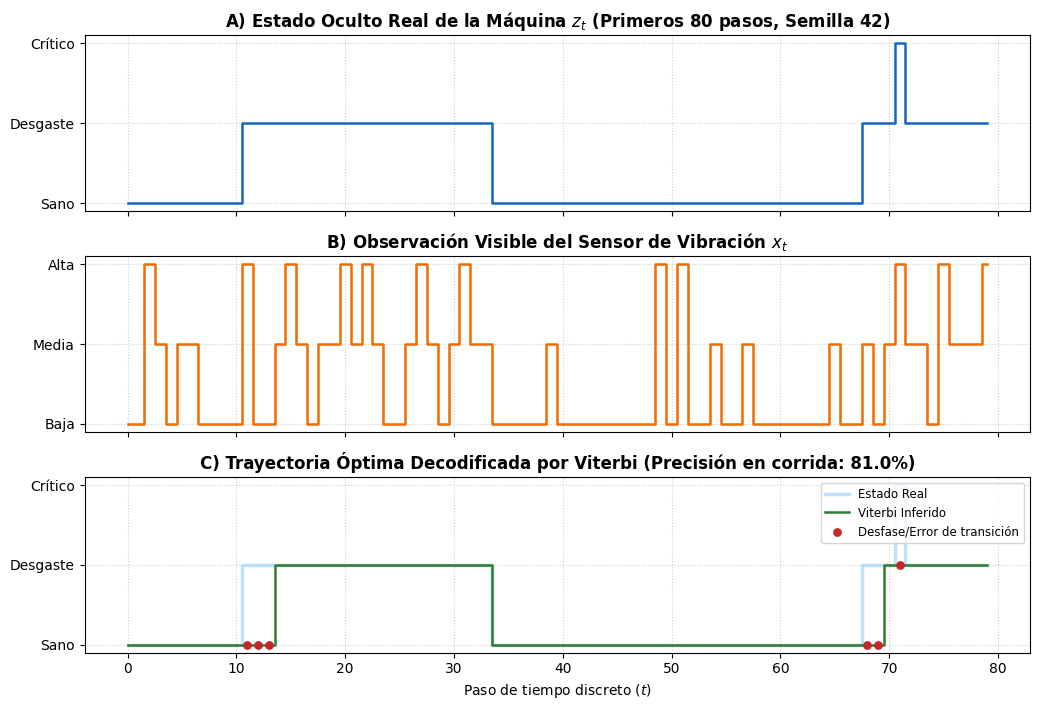

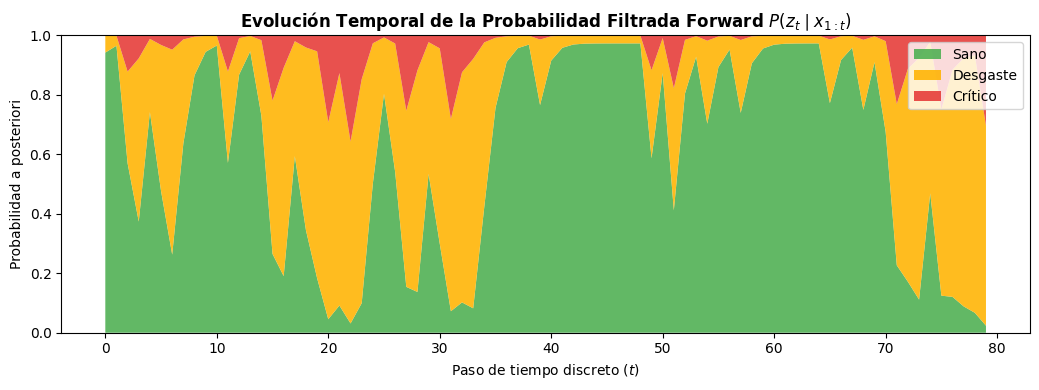

In [ ]:
N = min(80, PASOS); t = np.arange(N)
fig, ax = plt.subplots(3, 1, figsize=(10.5, 7.2), sharex=True)
ax[0].step(t, z[:N], where='mid', color='#1565c0', lw=1.8)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(ESTADOS)
ax[0].set_title('A) Estado Oculto Real de la Máquina $z_t$ (Primeros 80 pasos, Semilla 42)', fontweight='bold')
ax[0].grid(True, linestyle=':', alpha=0.6)

ax[1].step(t, x[:N], where='mid', color='#ef6c00', lw=1.8)
ax[1].set_yticks(range(3)); ax[1].set_yticklabels(OBSERV)
ax[1].set_title('B) Observación Visible del Sensor de Vibración $x_t$', fontweight='bold')
ax[1].grid(True, linestyle=':', alpha=0.6)

ax[2].step(t, z[:N], where='mid', color='#90caf9', lw=2.5, alpha=0.55, label='Estado Real')
ax[2].step(t, zv[:N], where='mid', color='#2e7d32', lw=1.8, label='Viterbi Inferido')
err_idx = np.where(z[:N] != zv[:N])[0]
if len(err_idx) > 0:
    ax[2].scatter(err_idx, zv[err_idx], color='#c62828', zorder=5, s=28, label='Desfase/Error de transición')
ax[2].set_yticks(range(3)); ax[2].set_yticklabels(ESTADOS)
ax[2].set_title(f'C) Trayectoria Óptima Decodificada por Viterbi (Precisión en corrida: {acc_v:.1%})', fontweight='bold')
ax[2].set_xlabel('Paso de tiempo discreto ($t$)')
ax[2].legend(loc='upper right', fontsize=8.5); ax[2].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout(); plt.savefig('results/secuencia.png', dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(10.5, 4.0))
ax.stackplot(t, alfa[:N].T, labels=ESTADOS, colors=['#4caf50', '#ffb300', '#e53935'], alpha=0.88)
ax.set_title('Evolución Temporal de la Probabilidad Filtrada Forward $P(z_t \\mid x_{1:t})$', fontweight='bold')
ax.set_xlabel('Paso de tiempo discreto ($t$)'); ax.set_ylabel('Probabilidad a posteriori')
ax.set_ylim(0, 1.0); ax.legend(loc='upper right', frameon=True)
plt.tight_layout(); plt.savefig('results/filtrado.png', dpi=300); plt.show()

## 5. Evaluación Multi-Escenario ($E_1$ a $E_4$, 500 Réplicas Monte Carlo c/u) e Intervalos de Confianza al 95%
Se ejecutan los 4 escenarios experimentales para evaluar la convergencia a la distribución estacionaria teórica y la sensibilidad frente a cambios en $\pi$, $A$ y $B$.

In [14]:
def evaluar_escenario(clave, cfg, pasos=PASOS, corridas=CORRIDAS, semilla_base=SEMILLA):
    pi_e, A_e, B_e = cfg['PI'], cfg['A'], cfg['B']
    rng_e = np.random.default_rng(semilla_base)
    if clave == 'E1_Base_Nominal':
        _ = simular(pasos, rng_e, pi_e, A_e, B_e)  # Mantiene secuencia exacta de semilla 42
    accs_v, accs_f, lls, retardos = [], [], [], []
    frec_est, frec_obs = np.zeros(3), np.zeros(3)
    trans, emis = np.zeros((3, 3)), np.zeros((3, 3))
    conf_matrix = np.zeros((3, 3), dtype=int)
    for _ in range(corridas):
        zz, xx = simular(pasos, rng_e, pi_e, A_e, B_e)
        zv_e = viterbi(xx, pi_e, A_e, B_e)
        ll_e, alfa_e, _ = forward(xx, pi_e, A_e, B_e)
        zf_e = alfa_e.argmax(axis=1)
        accs_v.append((zv_e == zz).mean()); accs_f.append((zf_e == zz).mean())
        lls.append(ll_e); retardos.append(calcular_retardo_deteccion(zz, zv_e))
        frec_est += np.bincount(zz, minlength=3); frec_obs += np.bincount(xx, minlength=3)
        for a_, b_ in zip(zz[:-1], zz[1:]): trans[a_, b_] += 1
        for s_, o_ in zip(zz, xx): emis[s_, o_] += 1
        for r_, p_ in zip(zz, zv_e): conf_matrix[r_, p_] += 1
    frec_est /= frec_est.sum(); frec_obs /= frec_obs.sum()
    A_hat = trans / trans.sum(axis=1, keepdims=True); B_hat = emis / emis.sum(axis=1, keepdims=True)
    pi_teo = estacionaria(A_e); obs_teo = pi_teo @ B_e
    recall_estados = np.diag(conf_matrix) / np.maximum(conf_matrix.sum(axis=1), 1)
    return {
        'nombre': cfg['nombre'], 'viterbi_stats': estadisticos_ic95(accs_v),
        'forward_stats': estadisticos_ic95(accs_f), 'll_stats': estadisticos_ic95(lls),
        'retardo_stats': estadisticos_ic95(retardos), 'accs_viterbi_raw': np.array(accs_v),
        'frec_est': frec_est, 'pi_teo': pi_teo, 'frec_obs': frec_obs, 'obs_teo': obs_teo,
        'err_A': float(np.abs(A_hat - A_e).max()), 'err_B': float(np.abs(B_hat - B_e).max()),
        'conf_matrix': conf_matrix, 'recall_estados': recall_estados
    }

resultados_escenarios = {k: evaluar_escenario(k, v) for k, v in ESCENARIOS.items()}
res_base = resultados_escenarios['E1_Base_Nominal']
vs_b = res_base['viterbi_stats']

print(f'=== Escenario Base E1 ({CORRIDAS} corridas x {PASOS} pasos) ===')
print(f"Precisión Viterbi: Media={vs_b['media']:.4f} | DE={vs_b['desv']:.4f} | Mín={vs_b['min']:.4f} | Máx={vs_b['max']:.4f} | IC95%=[{vs_b['ic95_inf']:.4f}, {vs_b['ic95_sup']:.4f}]")
print(f"Error máx. |A_hat - A| = {res_base['err_A']:.4f} | Error máx. |B_hat - B| = {res_base['err_B']:.4f}\n")

filas_comp = []
for k, r in resultados_escenarios.items():
    v, fw, ll_s, ret_s = r['viterbi_stats'], r['forward_stats'], r['ll_stats'], r['retardo_stats']
    filas_comp.append({
        'Escenario': r['nombre'],
        'Viterbi Media': round(v['media'], 4), 'Viterbi DE': round(v['desv'], 4),
        'Viterbi Mín': round(v['min'], 4), 'Viterbi Máx': round(v['max'], 4),
        'Viterbi IC95% Inf': round(v['ic95_inf'], 4), 'Viterbi IC95% Sup': round(v['ic95_sup'], 4),
        'Forward Media': round(fw['media'], 4), 'Forward DE': round(fw['desv'], 4),
        'Log-Verosim.': round(ll_s['media'], 2), 'Retardo (pasos)': round(ret_s['media'], 2),
        'Sim Sano': round(float(r['frec_est'][0]), 4), 'Sim Desgaste': round(float(r['frec_est'][1]), 4),
        'Sim Crítico': round(float(r['frec_est'][2]), 4), 'Recall Crítico': round(float(r['recall_estados'][2]), 4)
    })

df_comparacion = pd.DataFrame(filas_comp)
df_comparacion.to_csv('results/comparacion_escenarios.csv', index=False)
display(df_comparacion)

=== Escenario Base E1 (500 corridas x 200 pasos) ===
Precisión Viterbi: Media=0.8183 | DE=0.0522 | Mín=0.6500 | Máx=0.9500 | IC95%=[0.8137, 0.8229]
Error máx. |A_hat - A| = 0.0051 | Error máx. |B_hat - B| = 0.0069



,Escenario,Viterbi Media,Viterbi DE,Viterbi Mín,Viterbi Máx,Viterbi IC95% Inf,Viterbi IC95% Sup,Forward Media,Forward DE,Log-Verosim.,Retardo (pasos),Sim Sano,Sim Desgaste,Sim Crítico,Recall Crítico
0,E1: Base (Operación Nominal),0.8183,0.0522,0.650,0.950,0.8137,0.8229,0.7652,0.0445,-189.32,0.41,0.5956,0.3274,0.0771,0.3385
1,E2: Inicio Crítico (Variación de π),0.8162,0.0519,0.655,0.955,0.8116,0.8207,0.7624,0.0441,-190.04,0.41,0.5867,0.3291,0.0842,0.3733
2,E3: Sobrecarga Industrial (Variación de A),0.7145,0.0527,0.565,0.845,0.7099,0.7191,0.6741,0.0371,-207.15,0.36,0.3853,0.3926,0.2221,0.4635
3,E4: Sensor Calibrado (Variación de B),0.9355,0.0238,0.830,0.990,0.9334,0.9376,0.8809,0.0266,-146.99,0.16,0.5955,0.3275,0.0770,0.7377


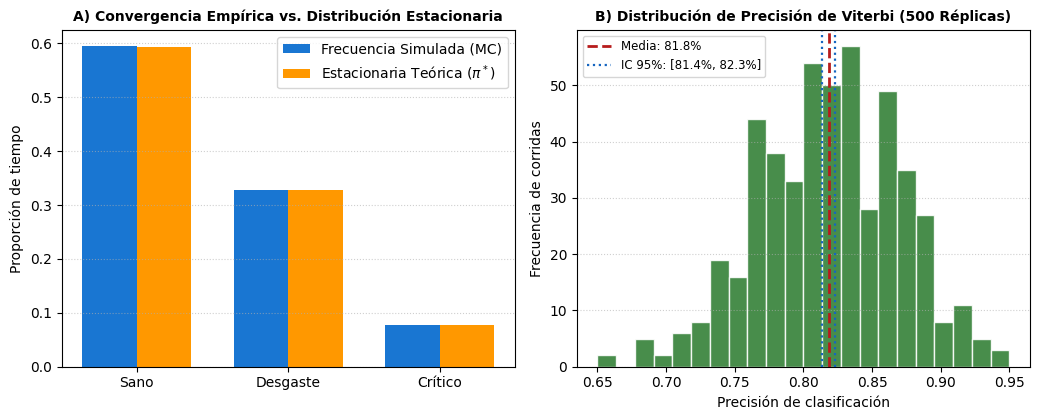

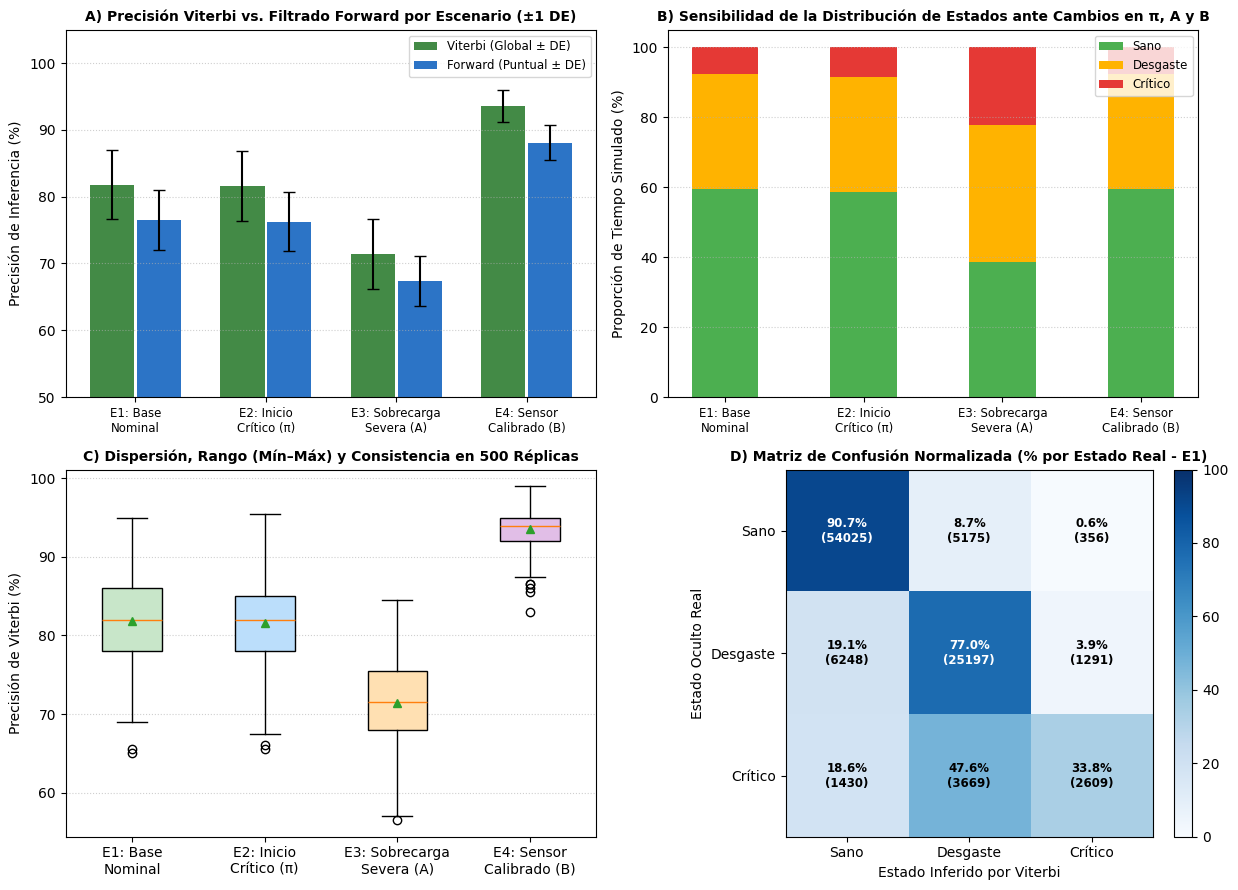

In [15]:
# Figura Monte Carlo Escenario Base
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.3))
idx = np.arange(3); wd = 0.36
ax[0].bar(idx - wd / 2, res_base['frec_est'], wd, label='Frecuencia Simulada (MC)', color='#1976d2')
ax[0].bar(idx + wd / 2, res_base['pi_teo'], wd, label=r'Estacionaria Teórica ($\pi^*$)', color='#ff9800')
ax[0].set_xticks(idx); ax[0].set_xticklabels(ESTADOS); ax[0].set_ylabel('Proporción de tiempo')
ax[0].set_title('A) Convergencia Empírica vs. Distribución Estacionaria', fontweight='bold', fontsize=10)
ax[0].legend(); ax[0].grid(axis='y', linestyle=':', alpha=0.6)

accs_b = res_base['accs_viterbi_raw']
ax[1].hist(accs_b, bins=22, color='#2e7d32', edgecolor='white', alpha=0.88)
ax[1].axvline(vs_b['media'], color='#b71c1c', linestyle='--', lw=2, label=f"Media: {vs_b['media']:.1%}")
ax[1].axvline(vs_b['ic95_inf'], color='#1565c0', linestyle=':', lw=1.6, label=f"IC 95%: [{vs_b['ic95_inf']:.1%}, {vs_b['ic95_sup']:.1%}]")
ax[1].axvline(vs_b['ic95_sup'], color='#1565c0', linestyle=':', lw=1.6)
ax[1].set_title('B) Distribución de Precisión de Viterbi (500 Réplicas)', fontweight='bold', fontsize=10)
ax[1].set_xlabel('Precisión de clasificación'); ax[1].set_ylabel('Frecuencia de corridas')
ax[1].legend(fontsize=8.5); ax[1].grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout(); plt.savefig('results/montecarlo.png', dpi=300); plt.show()

# Figura Comparativa de los 4 Escenarios + Matriz de Confusión
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.0))
nombres_cortos = ['E1: Base\nNominal', 'E2: Inicio\nCrítico (π)', 'E3: Sobrecarga\nSevera (A)', 'E4: Sensor\nCalibrado (B)']
claves_ord = ['E1_Base_Nominal', 'E2_Inicio_Critico', 'E3_Degradacion_Severa', 'E4_Sensor_Alta_Precision']
x_pos = np.arange(len(claves_ord))
v_means = [resultados_escenarios[k]['viterbi_stats']['media'] * 100 for k in claves_ord]
v_stds = [resultados_escenarios[k]['viterbi_stats']['desv'] * 100 for k in claves_ord]
f_means = [resultados_escenarios[k]['forward_stats']['media'] * 100 for k in claves_ord]
f_stds = [resultados_escenarios[k]['forward_stats']['desv'] * 100 for k in claves_ord]

axes[0, 0].bar(x_pos - 0.18, v_means, 0.34, yerr=v_stds, capsize=4, label='Viterbi (Global ± DE)', color='#2e7d32', alpha=0.9)
axes[0, 0].bar(x_pos + 0.18, f_means, 0.34, yerr=f_stds, capsize=4, label='Forward (Puntual ± DE)', color='#1565c0', alpha=0.9)
axes[0, 0].set_xticks(x_pos); axes[0, 0].set_xticklabels(nombres_cortos, fontsize=8.5)
axes[0, 0].set_ylabel('Precisión de Inferencia (%)'); axes[0, 0].set_ylim(50, 105)
axes[0, 0].set_title('A) Precisión Viterbi vs. Filtrado Forward por Escenario (±1 DE)', fontweight='bold', fontsize=10)
axes[0, 0].legend(fontsize=8.5); axes[0, 0].grid(axis='y', linestyle=':', alpha=0.6)

f_sano = [resultados_escenarios[k]['frec_est'][0] * 100 for k in claves_ord]
f_desg = [resultados_escenarios[k]['frec_est'][1] * 100 for k in claves_ord]
f_crit = [resultados_escenarios[k]['frec_est'][2] * 100 for k in claves_ord]
axes[0, 1].bar(x_pos, f_sano, 0.48, label='Sano', color='#4caf50')
axes[0, 1].bar(x_pos, f_desg, 0.48, bottom=f_sano, label='Desgaste', color='#ffb300')
axes[0, 1].bar(x_pos, f_crit, 0.48, bottom=np.array(f_sano) + np.array(f_desg), label='Crítico', color='#e53935')
axes[0, 1].set_xticks(x_pos); axes[0, 1].set_xticklabels(nombres_cortos, fontsize=8.5)
axes[0, 1].set_ylabel('Proporción de Tiempo Simulado (%)')
axes[0, 1].set_title('B) Sensibilidad de la Distribución de Estados ante Cambios en π, A y B', fontweight='bold', fontsize=10)
axes[0, 1].legend(loc='upper right', fontsize=8.5); axes[0, 1].grid(axis='y', linestyle=':', alpha=0.6)

datos_box = [resultados_escenarios[k]['accs_viterbi_raw'] * 100 for k in claves_ord]
bp = axes[1, 0].boxplot(datos_box, tick_labels=nombres_cortos, patch_artist=True, showmeans=True)
for patch, col in zip(bp['boxes'], ['#c8e6c9', '#bbdefb', '#ffe0b2', '#e1bee7']): patch.set_facecolor(col)
axes[1, 0].set_ylabel('Precisión de Viterbi (%)')
axes[1, 0].set_title('C) Dispersión, Rango (Mín–Máx) y Consistencia en 500 Réplicas', fontweight='bold', fontsize=10)
axes[1, 0].grid(axis='y', linestyle=':', alpha=0.6)

cm = res_base['conf_matrix'].astype(float)
cm_norm = (cm / cm.sum(axis=1, keepdims=True)) * 100
im = axes[1, 1].imshow(cm_norm, cmap='Blues', vmin=0, vmax=100)
axes[1, 1].set_xticks(range(3)); axes[1, 1].set_yticks(range(3))
axes[1, 1].set_xticklabels(ESTADOS); axes[1, 1].set_yticklabels(ESTADOS)
axes[1, 1].set_xlabel('Estado Inferido por Viterbi'); axes[1, 1].set_ylabel('Estado Oculto Real')
axes[1, 1].set_title('D) Matriz de Confusión Normalizada (% por Estado Real - E1)', fontweight='bold', fontsize=10)
for i in range(3):
    for j in range(3):
        c_txt = 'white' if cm_norm[i, j] > 50 else 'black'
        axes[1, 1].text(j, i, f'{cm_norm[i, j]:.1f}%\n({int(cm[i, j])})', ha='center', va='center', color=c_txt, fontsize=8.5, fontweight='bold')
fig.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04)
plt.tight_layout(); plt.savefig('results/comparacion_escenarios.png', dpi=300); plt.show()

## 6. Aprendizaje No Supervisado con Baum-Welch (Problema 3 de Rabiner)
Demostración de estimación de las matrices $\hat{A}$ y $\hat{B}$ únicamente a partir de secuencias de observación de vibración sin etiquetas de estado.

In [16]:
rng_bw = np.random.default_rng(SEMILLA + 100)
secuencias_bw = [simular(PASOS, rng_bw, PI, A, B)[1] for _ in range(40)]
A_init_pert = np.array([[0.80, 0.15, 0.05], [0.10, 0.75, 0.15], [0.30, 0.20, 0.50]])
B_init_pert = np.array([[0.65, 0.25, 0.10], [0.25, 0.50, 0.25], [0.10, 0.30, 0.60]])
pi_init_pert = np.array([0.70, 0.20, 0.10])

pi_bw, A_bw, B_bw, hist_ll = baum_welch(secuencias_bw, A_init_pert, B_init_pert, pi_init_pert, max_iter=35)
print(f'Iteraciones ejecutadas: {len(hist_ll)} | Log-verosimilitud inicial: {hist_ll[0]:.2f} -> final: {hist_ll[-1]:.2f}')
print(f'Error máx. |B_bw - B| = {np.abs(B_bw - B).max():.4f}')
display(pd.DataFrame(B_bw.round(3), index=ESTADOS, columns=['Vib. ' + o for o in OBSERV]).rename_axis('Matriz B Estimada por Baum-Welch'))

Iteraciones ejecutadas: 35 | Log-verosimilitud inicial: -194.50 -> final: -186.94
Error máx. |B_bw - B| = 0.0580


,Vib. Baja,Vib. Media,Vib. Alta
Matriz B Estimada por Baum-Welch,,,
Sano,0.763,0.201,0.036
Desgaste,0.202,0.577,0.222
Crítico,0.108,0.201,0.691
